# Course-End Project 2: Creating Designs with OpenAI and Gradio

## Objective
Create a simple web application that generates customized images/designs from text prompts using OpenAI GPT-Image-2 and Gradio.

This version is adapted for the JupyterLab environment and uses the `gpt-image-2` model.


## 1. Import Libraries


In [1]:
import openai
import gradio as gr
import base64
from PIL import Image
from io import BytesIO


## 2. Set OpenAI API Key

Replace the placeholder with your own API key.


In [2]:
import os
from dotenv import load_dotenv, find_dotenv

_ =load_dotenv(find_dotenv())
openai.api_key = os.getenv("OPENAI_API_KEY")

print("API key loaded")

print("OpenAI version:", openai.__version__)
print("API key configured:", bool(openai.api_key))


API key loaded
OpenAI version: 0.28.1
API key configured: True


## 3. Create the Image Generation Function

GPT-Image-2 returns image data as Base64. Therefore, we do **not** look for `response["data"][0]["url"]` and do not use `requests` to download an image URL.


In [3]:
def generate_image(prompt):
    if not prompt or not prompt.strip():
        return None

    try:
        response = openai.Image.create(
            model="gpt-image-2",
            prompt=prompt,
            n=1,
            size="1024x1024"
        )

        result = response["data"][0]

        # GPT-Image-2 returns Base64 image data
        image_data = base64.b64decode(result["b64_json"])
        image = Image.open(BytesIO(image_data))

        return image

    except Exception as e:
        print("Image generation error:", e)
        return None


## 4. Test the Function


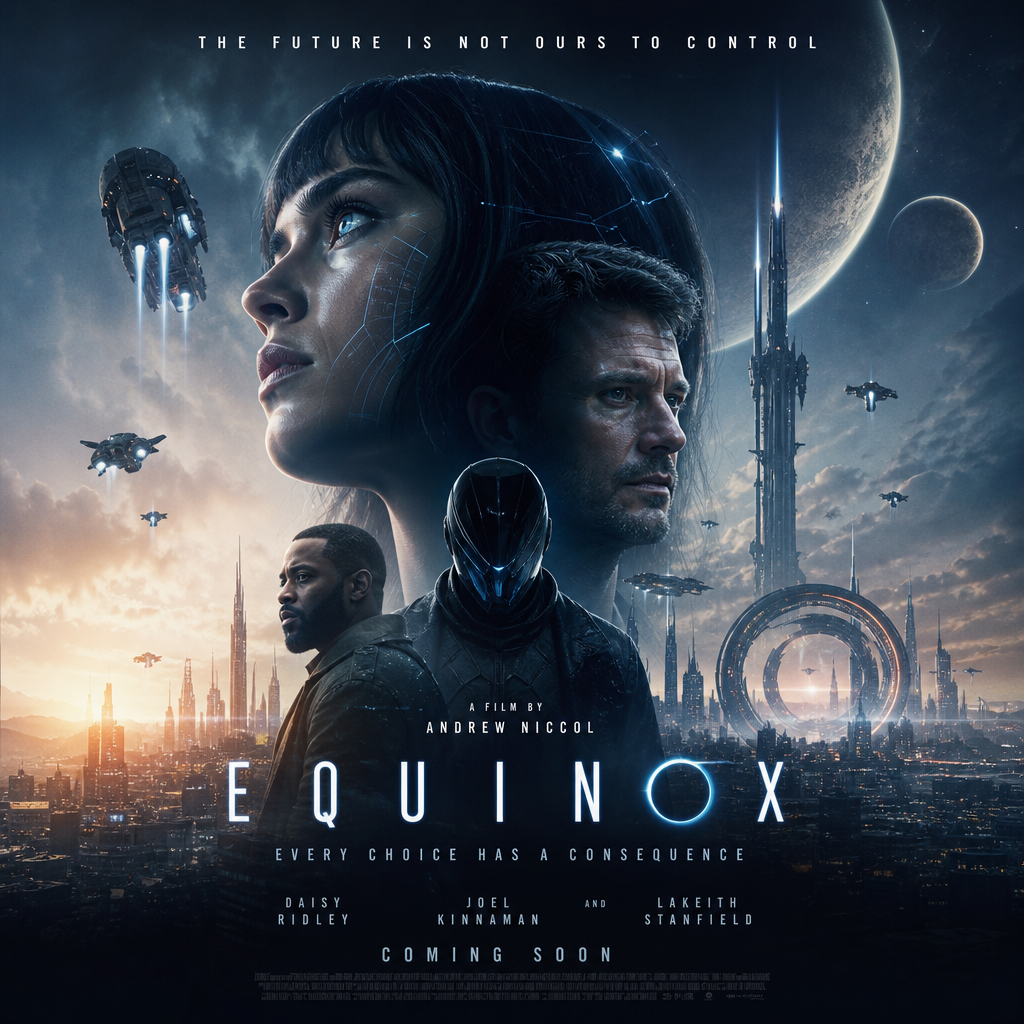

In [4]:
prompt = "A futuristic movie poster for a science fiction film"
image = generate_image(prompt)
display(image)


## 5. Create the Gradio Interface

The following version is suitable for a remote JupyterLab environment. It does not use `share=True`, so it does not depend on the Gradio FRPC sharing component.


In [8]:
demo = gr.Interface(
    fn=generate_image,
    inputs=gr.Textbox(
        label="Design Prompt",
        placeholder="Example: A futuristic movie poster"
    ),
    outputs=gr.Image(label="Generated Design"),
    title="AI Design Generator",
    description="Enter a text prompt to generate a creative design using GPT-Image-2."
)

demo.launch(
    server_name="0.0.0.0",
    share=True,
    inline=True
)


* Running on local URL:  http://0.0.0.0:7868
* Running on public URL: https://f087c0873f0c7a913f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## JupyterLab Access

If JupyterLab is running on a remote server, do not open `127.0.0.1` from your local computer.

For port `7863`, use your JupyterLab server's proxy URL:

```text
/proxy/7863/
```

For example, if your JupyterLab address is:

```text
https://your-lab-server/user/name/lab
```

the Gradio application is typically available at:

```text
https://your-lab-server/user/name/proxy/7863/
```


## Example Prompts

- A futuristic movie poster for a science fiction film
- A colorful promotional banner for a new streaming series
- A dramatic adventure movie poster
- A minimal digital marketing banner for a premium streaming service
